<p class="hz-kicker">Session 2 · Data analysis with pandas</p>

# Cleaning the customer base

The customer file you opened last week is full of copies, typos and impossible values. Today you make it trustworthy, write down every decision you take, and find the first patterns behind the monthly bill and behind churn.
<ul class="hz-lesson-meta"><li>≈ 85 min</li><li>10 ideas</li><li>Runs in your browser</li><li>Advance 2</li></ul>

## <span class="hz-step-n">01</span> Previously at Cordillera Mobile

Last week you joined the analytics team, loaded `cordillera_mobile.csv` and took a first look: 5,075 rows, 15 columns, some missing values and some duplicate rows. Two teams are waiting for answers:

- the **commercial team**: *what drives a customer's monthly bill?*
- the **retention team**: *which customers are about to cancel, and who should we call?*

Neither question can be answered with dirty data. A customer stored twice counts twice; one bill of 4,689 USD drags every average. Today you will:

1. look inside a DataFrame and select exactly the rows and columns you need,
2. audit the file and clean it, with a reason for every decision,
3. find the first patterns with `groupby` and four charts.

That is exactly what **Advance 2** asks of your team.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import PercentFormatter

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 120)

RAW = "https://raw.githubusercontent.com/hizocar/usm-course-intensivo/main/docs/datasets/cordillera_mobile.csv"
CLEAN = "https://raw.githubusercontent.com/hizocar/usm-course-intensivo/main/docs/datasets/cordillera_mobile_clean.csv"

raw = pd.read_csv(RAW)
print(f"Raw file: {raw.shape[0]:,} rows and {raw.shape[1]} columns")

Raw file: 5,075 rows and 15 columns


## <span class="hz-step-n">02</span> Anatomy of a DataFrame

Before you clean anything, know what you are holding. `raw` is a **DataFrame**: a table with

- **rows**, one per customer, labelled by the **index** (0, 1, 2… by default),
- **columns**, one per variable, each with a **dtype**: `object` for text, `int64` for whole numbers, `float64` for decimals,
- **values**, the data itself.

Take out one column and you get a **Series**: one variable for every customer, with the index still attached. Three methods are your first look at any new table: `head()` shows the first rows, `info()` lists the columns with their dtypes and non-missing counts, and `describe()` summarises the numeric columns.

<div class="hz-widget" data-widget="df-anatomy">
<p>▶ Interactive explainer: <a href="https://hizocar.github.io/usm-course-intensivo/classes/Session_2_Cleaning/">open this class on the course website</a> to use it.</p>
</div>

In [2]:
raw.head()

,customer_id,signup_date,age,region,plan,contract,tenure_months,data_gb,call_minutes,intl_roaming,support_tickets,autopay,payment_method,monthly_bill,churned
0,CM-12254,2022-07-04,34,Metropolitana,Basic,12 months,50,NaN,270,0,2,1,NaN,25.46,0
1,CM-10173,2026-06-26,31,Centro,Plus,12 months,3,19.0,310,0,0,0,Debit card,37.05,1
2,CM-11339,2020-05-29,38,Centro,Prepaid,Month-to-month,76,3.6,165,0,0,1,Credit card,11.43,0
3,CM-13440,2019-11-02,31,Centro,Unlimited,12 months,82,17.8,248,0,2,0,Debit card,40.97,0
4,CM-10214,2022-07-01,34,Metropolitana,Basic,Month-to-month,50,4.3,240,0,0,0,Cash,19.18,1


In [3]:
raw.info()
print()
print(type(raw["monthly_bill"]))     # one column → a Series

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5075 entries, 0 to 5074
Data columns (total 15 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   customer_id      5075 non-null   object 
 1   signup_date      5075 non-null   object 
 2   age              5075 non-null   int64  
 3   region           5075 non-null   object 
 4   plan             5075 non-null   object 
 5   contract         5075 non-null   object 
 6   tenure_months    5075 non-null   int64  
 7   data_gb          4874 non-null   float64
 8   call_minutes     5075 non-null   int64  
 9   intl_roaming     5075 non-null   int64  
 10  support_tickets  5075 non-null   int64  
 11  autopay          5075 non-null   int64  
 12  payment_method   4921 non-null   object 
 13  monthly_bill     5075 non-null   float64
 14  churned          5075 non-null   int64  
dtypes: float64(2), int64(7), object(6)
memory usage: 594.9+ KB

<class 'pandas.core.series.Series'>


In [4]:
raw.describe().round(1)

,age,tenure_months,data_gb,call_minutes,intl_roaming,support_tickets,autopay,monthly_bill,churned
count,5075.0,5075.0,4874.0,5075.0,5075.0,5075.0,5075.0,5075.0,5075.0
mean,38.7,41.7,12.8,224.3,0.1,0.8,0.5,33.3,0.2
std,29.4,23.9,11.5,126.0,0.3,0.9,0.5,109.2,0.4
min,-1.0,0.0,0.3,8.0,0.0,0.0,0.0,-36.1,0.0
25%,29.0,21.0,4.9,132.0,0.0,0.0,0.0,19.3,0.0
50%,38.0,42.0,9.1,201.0,0.0,1.0,0.0,29.0,0.0
75%,46.0,62.0,16.5,292.0,0.0,1.0,1.0,41.7,0.0
max,999.0,83.0,87.4,890.0,1.0,6.0,1.0,4689.0,1.0


Read `info()` like an auditor. Every column has 5,075 non-null values except `data_gb` and `payment_method`: those have missing values. The dtypes make sense: text is `object`, counts are `int64`, gigabytes and money are `float64`. A bill stored as `object` would have warned us that something non-numeric was hiding in it.

**Spot the dirt already.** `describe()` says the youngest customer is −1 years old and the oldest 999. The lowest bill is −36.1 USD and the highest 4,689 USD, while three quarters of the bills are below 41.7 USD. A summary table is the cheapest data quality check there is: run it on every new dataset.

<div class="hz-widget" data-widget="quiz">
<script type="application/json">{"q": "What does <code>raw['monthly_bill']</code> give you?", "options": ["A DataFrame with one column", "A Series: the bill of every customer, with the index attached", "A Python list of numbers"], "answer": 1, "why": "One column name in single brackets returns a Series. Double brackets, <code>raw[['monthly_bill']]</code>, would return a one-column DataFrame.", "code": false}</script>
</div>

## <span class="hz-step-n">03</span> Selecting rows and columns

Most questions start by narrowing the table: *only these columns*, *only that customer*. Square brackets pick columns by name: `raw["plan"]` gives a Series, `raw[["plan", "monthly_bill"]]` (double brackets) a DataFrame.

For rows, pandas has two tools, and mixing them up is the classic beginner bug:

- **`.loc[rows, columns]`** selects by **label**: the names in the index and the column names. A slice **includes** its stop.
- **`.iloc[rows, columns]`** selects by **position**: 0, 1, 2… like a Python list. A slice **excludes** its stop.

With the default index (0, 1, 2…) labels and positions look the same. Make `customer_id` the index and they part ways.

<div class="hz-widget" data-widget="loc-iloc">
<p>▶ Interactive explainer: <a href="https://hizocar.github.io/usm-course-intensivo/classes/Session_2_Cleaning/">open this class on the course website</a> to use it.</p>
</div>

In [5]:
customers = raw.set_index("customer_id")   # the IDs become the row labels
customers.head(3)

,signup_date,age,region,plan,contract,tenure_months,data_gb,call_minutes,intl_roaming,support_tickets,autopay,payment_method,monthly_bill,churned
customer_id,,,,,,,,,,,,,,
CM-12254,2022-07-04,34,Metropolitana,Basic,12 months,50,NaN,270,0,2,1,NaN,25.46,0
CM-10173,2026-06-26,31,Centro,Plus,12 months,3,19.0,310,0,0,0,Debit card,37.05,1
CM-11339,2020-05-29,38,Centro,Prepaid,Month-to-month,76,3.6,165,0,0,1,Credit card,11.43,0


In [6]:
print(customers.loc["CM-10004", "plan"])    # by label: customer CM-10004, column "plan"
print(customers.iloc[0, 3])                 # by position: first row, fourth column

try:
    customers.loc[2]                        # there is no customer labelled 2
except Exception as e:
    print(type(e).__name__, "→", e)

Basic
Basic
KeyError → 2


In [7]:
customers.iloc[0:3, 0:4]     # positions 0, 1, 2 and columns 0 to 3: the stops are excluded

,signup_date,age,region,plan
customer_id,,,,
CM-12254,2022-07-04,34,Metropolitana,Basic
CM-10173,2026-06-26,31,Centro,Plus
CM-11339,2020-05-29,38,Centro,Prepaid


In [8]:
customers.loc["CM-12254":"CM-11339", "age":"plan"]     # labels: both stops are included

,age,region,plan
customer_id,,,
CM-12254,34,Metropolitana,Basic
CM-10173,31,Centro,Plus
CM-11339,38,Centro,Prepaid


Same three customers, two addresses: `iloc[0:3]` stops *before* position 3, and `loc[:"CM-11339"]` stops *at* the label `CM-11339`, included. And `loc[2]` fails because no customer is *called* 2.

<div class="hz-widget" data-widget="quiz">
<script type="application/json">{"q": "With <code>customer_id</code> as the index, how many rows do <code>customers.iloc[0:3]</code> and <code>customers.loc['CM-12254':'CM-11339']</code> return? (<code>CM-11339</code> is the third row.)", "options": ["3 and 3", "3 and 2", "2 and 3", "An error: loc only takes numbers"], "answer": 0, "why": "iloc stops before position 3, so it returns positions 0, 1 and 2. loc includes the stop label, so it returns CM-12254 through CM-11339: the same three customers.", "code": false}</script>
</div>

## <span class="hz-step-n">04</span> Filtering with conditions

The retention team's first request: *month-to-month customers with 3 or more support tickets*. They can leave any day, and they are unhappy.

A comparison on a column, like `raw["contract"] == "Month-to-month"`, gives a **boolean mask**: a Series of True/False, one per customer. Put the mask inside `raw[...]` and only the True rows survive. Combine masks with `&` (and), `|` (or) and `~` (not), with **each condition in its own parentheses**. Two helpers save typing: `isin([...])` for "one of these values" and `between(a, b)` for a range, both ends included.

<div class="hz-widget" data-widget="mask-filter">
<p>▶ Interactive explainer: <a href="https://hizocar.github.io/usm-course-intensivo/classes/Session_2_Cleaning/">open this class on the course website</a> to use it.</p>
</div>

In [9]:
m2m = raw["contract"] == "Month-to-month"
print(m2m.head())
# True counts as 1 and False as 0: sum() counts the Trues, mean() gives their share
print(f"{m2m.sum():,} customers are month-to-month ({m2m.mean():.1%})")

0    False
1    False
2     True
3    False
4     True
Name: contract, dtype: bool
2,979 customers are month-to-month (58.7%)


In [10]:
many_tickets = raw["support_tickets"] >= 3
call_list = raw[m2m & many_tickets]
print(f"Month-to-month with 3+ tickets: {len(call_list)} customers")
print(f"Their churn rate: {call_list['churned'].mean():.1%}, against {raw['churned'].mean():.1%} overall")
# still the raw file, duplicates included: we recount this list after cleaning

Month-to-month with 3+ tickets: 151 customers
Their churn rate: 68.2%, against 16.5% overall


In [11]:
young = raw["age"].between(18, 24)
big_plan = raw["plan"].isin(["Plus", "Unlimited"])
print(f"Aged 18 to 24:          {young.sum():,}")
print(f"On Plus or Unlimited:   {big_plan.sum():,}")
print(f"...ignoring upper/lower case: {raw['plan'].str.lower().isin(['plus', 'unlimited']).sum():,}")

Aged 18 to 24:          682
On Plus or Unlimited:   2,186
...ignoring upper/lower case: 2,309


The two plan counts differ: `isin` compares text exactly, so `"PLUS"` and `"unlimited"` slip through. The data is lying to our filters, and that is the next section.

First, the most common filtering error. Python applies `&` before `==` and `>=`, so without parentheses it tries to compute `"Month-to-month" & raw["support_tickets"]`, which makes no sense. Parentheses around each condition fix it. (Writing `and` instead of `&` fails too: `and` wants a single True or False, not a whole column of them.)

In [12]:
try:
    raw[raw["contract"] == "Month-to-month" & raw["support_tickets"] >= 3]   # no parentheses
except Exception as e:
    print(type(e).__name__, "→", e)

fixed = raw[(raw["contract"] == "Month-to-month") & (raw["support_tickets"] >= 3)]
print(f"With parentheses: {len(fixed)} rows")

TypeError → Cannot perform 'rand_' with a dtyped [int64] array and scalar of type [bool]
With parentheses: 151 rows


<div class="hz-widget" data-widget="quiz">
<script type="application/json">{"q": "What does <code>(df['contract'] == 'Month-to-month') &amp; (df['support_tickets'] &gt;= 3)</code> return?", "options": ["The rows that meet both conditions", "A True/False Series, True only where both conditions are True", "A single True or False", "A True/False Series, True where at least one condition is True"], "answer": 1, "why": "Combining two masks with <code>&amp;</code> gives another mask, row by row. Only <code>df[mask]</code> turns it into rows. True where at least one holds is <code>|</code>.", "code": false}</script>
</div>

## <span class="hz-step-n">05</span> The data quality audit

Now point those tools at the data itself. An audit asks one question per kind of problem, answers it with code, and writes down the count:

1. Are there **duplicate rows**?
2. Are categories **spelled consistently**?
3. Are there **impossible values** (ages, bills)?
4. What is **missing**?

Run every check on the raw file **before** changing anything, so you know what you are about to fix. The explainer runs the whole pipeline at once; the cells below do the audit, and section 06 does the cleaning.

<div class="hz-widget" data-widget="cleaning-audit">
<p>▶ Interactive explainer: <a href="https://hizocar.github.io/usm-course-intensivo/classes/Session_2_Cleaning/">open this class on the course website</a> to use it.</p>
</div>

In [13]:
# Check 1: duplicates
print(f"Exact duplicate rows: {raw.duplicated().sum()}")
raw[raw.duplicated(keep=False)].sort_values("customer_id").head(4)

Exact duplicate rows: 75


,customer_id,signup_date,age,region,plan,contract,tenure_months,data_gb,call_minutes,intl_roaming,support_tickets,autopay,payment_method,monthly_bill,churned
1894,CM-10277,2020-01-31,45,Sur,Prepaid,Month-to-month,79,2.4,201,1,0,1,Debit card,15.65,0
3098,CM-10277,2020-01-31,45,Sur,Prepaid,Month-to-month,79,2.4,201,1,0,1,Debit card,15.65,0
2744,CM-10340,2021-10-24,35,Metropolitana,Unlimited,12 months,59,21.1,457,0,1,1,Bank transfer,46.51,0
1853,CM-10340,2021-10-24,35,Metropolitana,Unlimited,12 months,59,21.1,457,0,1,1,Bank transfer,46.51,0


`duplicated()` marks a row that is identical, column by column, to an earlier one; `keep=False` marks both copies so you can see the pairs. **Check 2, categories:** `value_counts()` lists every distinct text and how often it appears.

In [14]:
print(raw["region"].value_counts())
print()
print("Spellings of region:", raw["region"].nunique())
print("Spellings of plan:  ", raw["plan"].nunique())
print(raw["region"].unique())

region
Metropolitana     2149
Centro             991
Sur                975
Norte              723
Metropolitana       45
metropolitana       43
norte               38
METROPOLITANA       33
NORTE               28
sur                 27
Sur                 23
Name: count, dtype: int64

Spellings of region: 11
Spellings of plan:   10
['Metropolitana' 'Centro' 'Sur' 'Norte' 'Metropolitana ' 'norte' 'Sur '
 'sur' 'metropolitana' 'METROPOLITANA' 'NORTE']


There are 4 regions and 4 plans, but pandas sees 11 and 10. `unique()` shows the quotes, which reveals the sneakiest ones: `'Sur '` and `'Metropolitana '` end with a space. A `groupby("region")` on this column would report 11 regions. **Check 3, impossible values:** an age must be between 18 and 100, and a bill between 0 and 300 USD (the most expensive plan costs 42 USD before extras).

In [15]:
# Check 3: impossible values
bad_age = ~raw["age"].between(18, 100)
print(f"Ages outside 18-100: {bad_age.sum()}")
print(raw.loc[bad_age, "age"].value_counts())
print()
negative = raw["monthly_bill"] < 0
huge = raw["monthly_bill"] > 300
print(f"Negative bills: {negative.sum()}    Bills above 300 USD: {huge.sum()}")
raw.loc[huge, ["customer_id", "plan", "monthly_bill"]]

Ages outside 18-100: 15
age
 0      7
 999    4
-1      4
Name: count, dtype: int64

Negative bills: 10    Bills above 300 USD: 5


,customer_id,plan,monthly_bill
152,CM-10319,Prepaid,1386.0
832,CM-11287,Plus,4119.0
2270,CM-11620,Plus,3458.0
2542,CM-12112,PLUS,4689.0
4093,CM-10247,Basic,2804.0


No plan costs thousands of dollars a month. These look like a lost decimal point: 4,689.00 on a Plus plan is almost surely 46.89. Negative bills could be refunds or typos; the file does not tell us which. **Check 4, missing values,** goes straight into the audit table, with all the other counts:

In [16]:
REGIONS = ["Metropolitana", "Centro", "Sur", "Norte"]
PLANS = ["Prepaid", "Basic", "Plus", "Unlimited"]

audit = pd.Series({
    "Duplicate rows": raw.duplicated().sum(),
    "Non-standard region": (~raw["region"].isin(REGIONS)).sum(),
    "Non-standard plan": (~raw["plan"].isin(PLANS)).sum(),
    "Age outside 18-100": bad_age.sum(),
    "Missing data_gb": raw["data_gb"].isna().sum(),
    "Missing payment_method": raw["payment_method"].isna().sum(),
    "Bill below 0 or above 300": (negative | huge).sum(),
}, name="count")      # raw.isna().sum() would list the missing values of every column
print(audit)
print(f"\nDirty values found: {audit.sum()}")

Duplicate rows                75
Non-standard region          237
Non-standard plan            228
Age outside 18-100            15
Missing data_gb              201
Missing payment_method       154
Bill below 0 or above 300     15
Name: count, dtype: int64

Dirty values found: 925


## <span class="hz-step-n">06</span> Cleaning, with decisions you can defend

Every problem needs a **decision**, and every decision needs a reason a manager would accept:

| Issue | Decision | Why |
|---|---|---|
| Exact duplicates | Drop the copies | A customer counted twice weighs double in every average |
| Inconsistent spelling | `strip()` + `title()` | Same region, same plan → same text |
| Age outside 18–100 | Make it missing, then fill with the median | The true age is unknowable; the median ignores extremes |
| Missing `data_gb` | Median **of the customer's plan** | Data use depends strongly on the plan |
| Missing `payment_method` | New category `"Unknown"` | Honest; we don't invent a payment method |
| Bill below 0 or above 300 | Drop the row | It is the commercial team's target: guessing it would invent the answer |

**Order matters.** Drop duplicates first, so copies don't count twice in the medians. Fix the spelling before using `plan` for group medians. As you go, write each decision into a log: at the end, the log *is* the cleaning summary table of Advance 2.

In [17]:
df = raw.copy()
log = []    # one entry per decision: this becomes the cleaning summary table

def record(issue, decision, rows):
    log.append({"issue": issue, "decision": decision, "rows affected": int(rows)})
    print(f"{issue}: {rows:,} rows → {decision}")

# 1. Duplicates
before = len(df)
df = df.drop_duplicates()
record("Exact duplicate rows", "Dropped, kept the first copy", before - len(df))

Exact duplicate rows: 75 rows → Dropped, kept the first copy


In [18]:
# 2. Spelling: strip spaces at both ends, then Title Case
for col in ["region", "plan"]:
    tidy = df[col].str.strip().str.title()
    changed = (tidy != df[col]).sum()
    df[col] = tidy
    record(f"Inconsistent spelling in {col}", "strip() + title()", changed)

print(df["region"].value_counts())

Inconsistent spelling in region: 236 rows → strip() + title()
Inconsistent spelling in plan: 227 rows → strip() + title()
region
Metropolitana    2228
Sur              1008
Centro            979
Norte             785
Name: count, dtype: int64


In [19]:
# 3. Impossible ages: unknown → missing → median
bad_age = ~df["age"].between(18, 100)
df.loc[bad_age, "age"] = np.nan
median_age = df["age"].median()
df["age"] = df["age"].fillna(median_age).astype("int64")   # whole years again
record("Impossible age (outside 18-100)", f"Set to NaN, filled with the median ({median_age:.0f})", bad_age.sum())

Impossible age (outside 18-100): 15 rows → Set to NaN, filled with the median (38)


For `data_gb` we want the median **of each plan**: a Prepaid customer uses far less data than an Unlimited one, so one overall median would be wrong for both. `groupby` is section 07; here read it as "one median per plan". `transform("median")` puts each row's own plan median next to it, so `fillna` can use it.

In [20]:
# 4. Missing values
print(df.groupby("plan")["data_gb"].median(), "\n")

n_gb = df["data_gb"].isna().sum()
plan_median = df.groupby("plan")["data_gb"].transform("median")
df["data_gb"] = df["data_gb"].fillna(plan_median)
record("Missing data_gb", "Filled with the median of the customer's plan", n_gb)

n_pay = df["payment_method"].isna().sum()
df["payment_method"] = df["payment_method"].fillna("Unknown")
record("Missing payment_method", 'New category "Unknown"', n_pay)

plan
Basic         7.1
Plus         14.1
Prepaid       3.7
Unlimited    27.5
Name: data_gb, dtype: float64 

Missing data_gb: 200 rows → Filled with the median of the customer's plan
Missing payment_method: 150 rows → New category "Unknown"


In [21]:
# 5. Impossible bills: drop the row
bad_bill = ~df["monthly_bill"].between(0, 300)
df = df[~bad_bill].reset_index(drop=True)
record("Impossible bill (below 0 or above 300 USD)", "Dropped the row", bad_bill.sum())

Impossible bill (below 0 or above 300 USD): 15 rows → Dropped the row


In [22]:
# The log becomes the table your manager (and Advance 2) wants to see
print(f"Rows: {len(raw):,} → {len(df):,} ({len(raw) - len(df)} removed)")
print(f"Missing values left: {df.isna().sum().sum()}")
assert df.shape == (4985, 15)

summary = pd.DataFrame(log)
summary

Rows: 5,075 → 4,985 (90 removed)
Missing values left: 0


,issue,decision,rows affected
0,Exact duplicate rows,"Dropped, kept the first copy",75
1,Inconsistent spelling in region,strip() + title(),236
2,Inconsistent spelling in plan,strip() + title(),227
3,Impossible age (outside 18-100),"Set to NaN, filled with the median (38)",15
4,Missing data_gb,Filled with the median of the customer's plan,200
5,Missing payment_method,"New category ""Unknown""",150
6,Impossible bill (below 0 or above 300 USD),Dropped the row,15


Last check: does our cleaning give exactly the clean file that sessions 3 to 5 start from? `assert_frame_equal` compares every value and every dtype, and raises an error at the first difference.

In [23]:
published = pd.read_csv(CLEAN)
pd.testing.assert_frame_equal(df, published)
print("Matches the published clean file")

Matches the published clean file


<div class="hz-widget" data-widget="quiz">
<script type="application/json">{"q": "Why do we fill a missing <code>data_gb</code> with the median <em>of the customer's plan</em> instead of the overall median?", "options": ["Because the overall median cannot be computed while there are missing values", "Because data use depends strongly on the plan, so the plan's median is a much closer guess", "Because pandas requires groupby before fillna", "Because it removes the outliers"], "answer": 1, "why": "A Prepaid customer uses about 3.7 GB and an Unlimited one about 27.5 GB. One overall number would be wrong for both. The more the guess uses what we know about the customer, the less it distorts the data.", "code": false}</script>
</div>

## <span class="hz-step-n">07</span> groupby: the first patterns

Clean data at last. The retention team's first question: *does churn depend on the contract?* That is a **groupby**: **split** the customers by contract, **apply** a calculation inside each group, **combine** the answers into one small table.

Because `churned` is 0/1, its **mean** in a group is the share of customers who left: the **churn rate**.

The explainer uses a toy example (stock prices) because the three moves are easier to watch on nine rows. Right after it, the same moves on our 4,985 customers.

<div class="hz-widget" data-widget="groupby">
<p>▶ Interactive explainer: <a href="https://hizocar.github.io/usm-course-intensivo/classes/Session_2_Cleaning/">open this class on the course website</a> to use it.</p>
</div>

In [24]:
print(f"Overall churn rate: {df['churned'].mean():.1%}\n")

churn_by_contract = df.groupby("contract")["churned"].mean().sort_values(ascending=False)
for contract, rate in churn_by_contract.items():
    print(f"{contract:<15} {rate:.1%}")
print()
churn_by_region = df.groupby("region")["churned"].mean().sort_values(ascending=False)
for region, rate in churn_by_region.items():
    print(f"{region:<14} {rate:.1%}")

Overall churn rate: 16.4%

Month-to-month  22.0%
12 months       8.9%
24 months       7.8%

Norte          27.6%
Metropolitana  15.4%
Sur            13.9%
Centro         12.4%


In [25]:
# Several numbers per group: agg takes a list. For the commercial team, the bill by plan.
bill_by_plan = df.groupby("plan")["monthly_bill"].agg(["count", "mean", "median"]).round(2)
bill_by_plan.sort_values("mean")

,count,mean,median
plan,,,
Prepaid,1193,14.79,14.28
Basic,1504,24.32,23.90
Plus,1438,39.29,39.03
Unlimited,850,46.95,46.44


In [26]:
churn_by_tickets = df.groupby("support_tickets")["churned"].agg(["count", "mean"]).round(3)
churn_by_tickets

,count,mean
support_tickets,,
0,2282,0.128
1,1746,0.138
2,688,0.218
3,208,0.524
4,54,0.426
5,5,0.200
6,2,0.500


Churn jumps at 3 tickets. (The rows with 5 or 6 tickets hold only a handful of customers: never trust a rate built on 2 people.) Now the retention team's call list, recounted on clean data:

In [27]:
call_list = df[(df["contract"] == "Month-to-month") & (df["support_tickets"] >= 3)]
print(f"Call list: {len(call_list)} customers, churn rate {call_list['churned'].mean():.1%}")

Call list: 147 customers, churn rate 68.7%


## <span class="hz-step-n">08</span> Charts that answer questions

A table of numbers convinces an analyst; a chart convinces a meeting. The rule: **start from the question, then pick the chart**.

- one numeric variable, how it spreads → **histogram**
- a number compared across categories → **box plot**
- a rate per category → **bar chart**
- two numbers, do they move together → **scatter plot**

Every chart gets a title, labelled axes, and **one sentence under it saying what it shows**. Advance 2 asks for exactly that.

<div class="hz-widget" data-widget="chart-chooser">
<p>▶ Interactive explainer: <a href="https://hizocar.github.io/usm-course-intensivo/classes/Session_2_Cleaning/">open this class on the course website</a> to use it.</p>
</div>

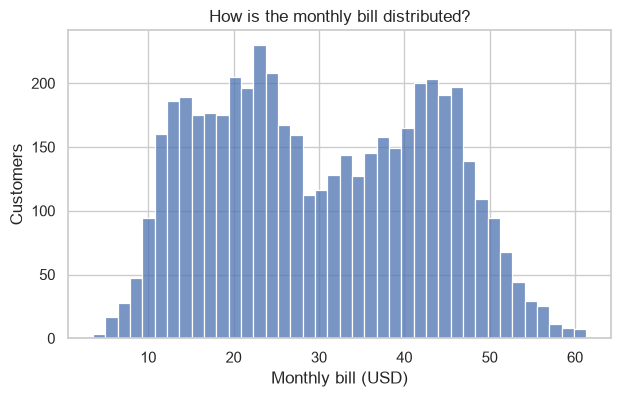

In [28]:
plt.figure(figsize=(7, 4))
sns.histplot(df, x="monthly_bill", bins=40)
plt.title("How is the monthly bill distributed?")
plt.xlabel("Monthly bill (USD)")
plt.ylabel("Customers")
plt.show()

**What it shows:** bills run from about 4 to 61 USD with **two humps**, one around 20–25 USD and one around 40–45 USD. Two humps usually mean two kinds of customers mixed together: here, the cheaper plans and the more expensive ones. No single "typical bill" describes this base.

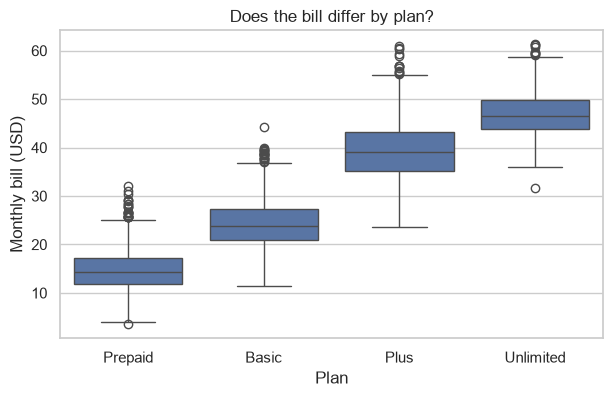

In [29]:
plan_order = ["Prepaid", "Basic", "Plus", "Unlimited"]

plt.figure(figsize=(7, 4))
sns.boxplot(df, x="plan", y="monthly_bill", order=plan_order)
plt.title("Does the bill differ by plan?")
plt.xlabel("Plan")
plt.ylabel("Monthly bill (USD)")
plt.show()

**What it shows:** the plan sets the level of the bill. Medians climb from 14.28 USD on Prepaid to 46.44 USD on Unlimited, and neighbouring boxes barely overlap. The dots beyond the whiskers are unusually high bills *within* a plan: worth a look, but possible, unlike the ones we removed.

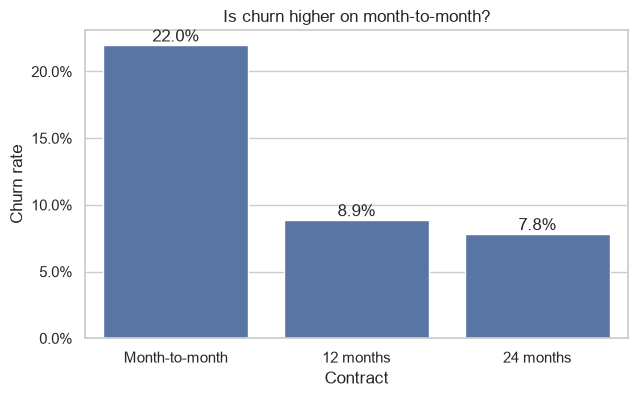

In [30]:
contract_order = ["Month-to-month", "12 months", "24 months"]

plt.figure(figsize=(7, 4))
ax = sns.barplot(df, x="contract", y="churned", order=contract_order, errorbar=None)
ax.bar_label(ax.containers[0], fmt="{:.1%}")
ax.yaxis.set_major_formatter(PercentFormatter(1))
plt.title("Is churn higher on month-to-month?")
plt.xlabel("Contract")
plt.ylabel("Churn rate")
plt.show()

**What it shows:** 22.0% of month-to-month customers churned, against 8.9% on 12-month and 7.8% on 24-month contracts. Customers without a contract leave almost three times as often as those on a 24-month one.

Correlation between data_gb and monthly_bill: 0.75


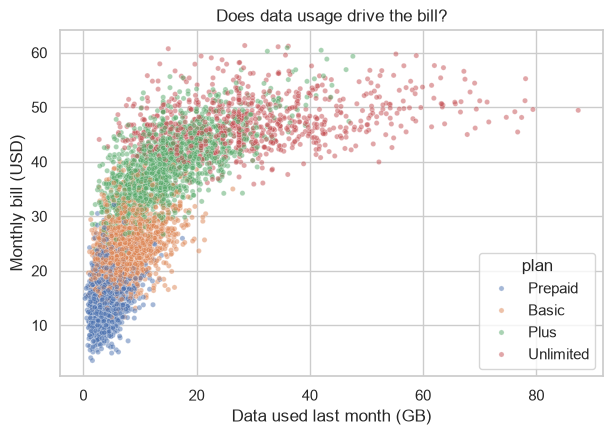

In [31]:
corr = df["data_gb"].corr(df["monthly_bill"])
print(f"Correlation between data_gb and monthly_bill: {corr:.2f}")

plt.figure(figsize=(7, 4.5))
sns.scatterplot(df, x="data_gb", y="monthly_bill", hue="plan", hue_order=plan_order, alpha=0.5, s=14)
plt.title("Does data usage drive the bill?")
plt.xlabel("Data used last month (GB)")
plt.ylabel("Monthly bill (USD)")
plt.show()

**What it shows:** more data, higher bill (correlation 0.75). Each plan forms its own band that rises with data, except Unlimited, which is almost flat: extra gigabytes cost those customers almost nothing. Data use matters, but *within* a plan.

<div class="hz-widget" data-widget="quiz">
<script type="application/json">{"q": "The retention team asks: <em>is churn higher in the Norte region than elsewhere?</em> Which chart answers it best?", "options": ["A histogram of <code>churned</code>", "A scatter plot of <code>region</code> against <code>churned</code>", "A bar chart of the churn rate (mean of <code>churned</code>) by region", "A box plot of <code>churned</code> by region"], "answer": 2, "why": "The question is a rate per category, so one bar per region, with height = share who churned. A 0/1 column makes histograms and box plots nearly empty, and a scatter of a category against 0/1 is just four stacks of dots.", "code": false}</script>
</div>

## <span class="hz-step-n">09</span> From charts to findings

A finding is not a number. It is a number **plus what it means for someone**. A good template:

> **What we see** (with the number) → **what it means for the business** → **what to look at next**.

First, the numbers we will quote, all in one place:

In [32]:
rest_rate = df.loc[df["region"] != "Norte", "churned"].mean()
print(f"Churn: month-to-month {churn_by_contract['Month-to-month']:.1%}, "
      f"12 months {churn_by_contract['12 months']:.1%}, 24 months {churn_by_contract['24 months']:.1%}")
print(f"Churn: Norte {churn_by_region['Norte']:.1%}, other regions {rest_rate:.1%}")
print(f"Call list (month-to-month, 3+ tickets): {len(call_list)} customers, churn {call_list['churned'].mean():.1%}")
print(f"Median bill: Prepaid {bill_by_plan.loc['Prepaid', 'median']:.2f}, Unlimited {bill_by_plan.loc['Unlimited', 'median']:.2f} USD")
print(f"Correlation data_gb vs monthly_bill: {corr:.2f}")

Churn: month-to-month 22.0%, 12 months 8.9%, 24 months 7.8%
Churn: Norte 27.6%, other regions 14.3%
Call list (month-to-month, 3+ tickets): 147 customers, churn 68.7%
Median bill: Prepaid 14.28, Unlimited 46.44 USD
Correlation data_gb vs monthly_bill: 0.75


**Finding 1 · Contracts keep customers.** Month-to-month customers churn at 22.0%, against 7.8% on 24-month contracts: almost three times as often. *For the retention team:* moving month-to-month customers onto a contract is the biggest lever we have seen so far; a small discount for switching is worth testing. *Next:* does the gap hold within every plan?

**Finding 2 · Complaints come before cancellations, especially in the north.** Norte churns at 27.6%, against 14.3% in the other regions, and month-to-month customers with 3 or more tickets churn at 68.7%. *For the retention team:* those 147 customers are the first call list, and Norte's complaints deserve a conversation with the network team. *Next:* what are Norte's tickets about?

**Finding 3 · The plan sets the bill; data use moves it within the plan.** The median bill goes from 14.28 USD on Prepaid to 46.44 USD on Unlimited, and data use correlates 0.75 with the bill. *For the commercial team:* to explain a bill, start from the plan and the gigabytes. *Next:* how many dollars does each extra GB add, once the plan is taken into account? That needs a model, and it is session 3.

Notice what these findings are **not**: they are not proof that a contract *causes* customers to stay. Customers who sign 24 months may simply be happier to begin with. Findings point where to look; models and experiments come later.

## <span class="hz-step-n">10</span> Your project this week

**[Advance 2 · Cleaning and exploratory analysis](https://hizocar.github.io/usm-course-intensivo/project/progress/#advance-2-cleaning-and-exploratory-analysis)** is due **Tuesday, November 10, 23:59**. It is today's class, done on your team's data. We did it with `monthly_bill` and `churned`; you do it with `Salary` (Case A) or `default` (Case B).

| Today with Cordillera | Case A · TalentCo (`Salary`) | Case B · FinTrust (`default`) |
|---|---|---|
| Audit: `duplicated()`, `value_counts()` on every text column, `describe()`, `isna().sum()` | Check the spellings of `Education_Level`, `Department`, `Region`, `Job_Level`; look for impossible `Age`, `Years_Experience` or a `Performance_Score` outside 1.0–5.0 | Check the spellings of `employment_type`, `loan_purpose`, `region`; look for a `credit_score` outside 300–850, a `debt_to_income_ratio` outside 0–1, impossible ages |
| One decision per issue, logged as you clean | Same `log` + `record()` pattern | Same `log` + `record()` pattern |
| Cleaning summary table: issue · decision · rows affected | `pd.DataFrame(log)` | `pd.DataFrame(log)` |
| `groupby` on the target | Average `Salary` by department, education, job level | Default rate (mean of `default`) by employment type, purpose, region |
| Four charts, one sentence each | e.g. histogram of `Salary`, box plot of `Salary` by `Job_Level`, scatter of `Years_Experience` vs `Salary` | e.g. bar chart of the default rate by `employment_type`, box plot of `credit_score` by `default` |
| Three findings with business meaning | For the people team | For the risk team |

**Tips for the workshop**

- Run the whole audit **before** you change anything, and keep its output in the notebook: it is the evidence for your decisions.
- Justify each decision in one line. "We dropped them" is not a justification; "a bill is our target and we cannot know the true value" is.
- At least one chart must relate a variable to the **target**: that is the point of the exploration.
- Run *Restart session and run all* before you submit. The notebook must run top to bottom.

**Next session · What drives the monthly bill?** The box plot showed that the plan sets the level of the bill, and the scatter plot that data use pushes it up. Next week the commercial team gets a model: a formula that estimates any customer's bill, says how many dollars each gigabyte adds, and is tested on customers it has never seen. Your clean data from this week is where it starts.